# Do scheduled-supply predictors improve daily demand forecasting?

Compare demand history with the same history plus scheduled departures and passenger-trip service hours. This is retrospective development, not a new independent prospective test. Both model families use exactly the same rows.

In [1]:
from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'data/processed/new_york').exists():
    root = root.parent
folder = root / 'data/processed/new_york/service_feature_experiment'
manifest = json.loads((folder / 'manifest.json').read_text())
pd.Series(manifest['counts'], name='eligible route/date rows')

train         3095
validation    1751
test          2281
Name: eligible route/date rows, dtype: int64

## Availability and pairing

An eligible schedule must pass the existing quality checks and have both contributing archive captures strictly before the target date. Capture dates are conservative archive-availability proxies, not verified original publisher timestamps. Demand features obey a 14-complete-day reporting assumption. Training ends March 31; validation ends May 17; testing covers June?July 2026.

In [2]:
audit = pd.read_csv(folder / 'schedule_availability.csv')
audit.groupby(['schedule_comparison_eligible','issue_time_schedule_eligible'], dropna=False).size().rename('rows')

schedule_comparison_eligible  issue_time_schedule_eligible
NaN                           False                           14965
False                         False                             823
True                          False                             113
                              True                            10257
Name: rows, dtype: int64

In [3]:
scores = pd.read_csv(folder / 'metrics.csv')
scores.round(3)

,split,model,rows,MAE,RMSE,WAPE
0,test,random_forest_demand,2281,649.975,1048.788,0.118
1,test,random_forest_service,2281,644.212,1041.867,0.117
2,test,ridge_demand,2281,1928.328,2173.585,0.351
3,test,ridge_service,2281,1820.348,2053.451,0.332
4,test,seasonal_mean4,2281,524.770,877.271,0.096
5,validation,random_forest_demand,1751,479.705,732.916,0.084
6,validation,random_forest_service,1751,479.239,732.639,0.084
7,validation,ridge_demand,1751,879.989,1063.769,0.154
8,validation,ridge_service,1751,815.022,1001.072,0.142
9,validation,seasonal_mean4,1751,490.515,705.301,0.086


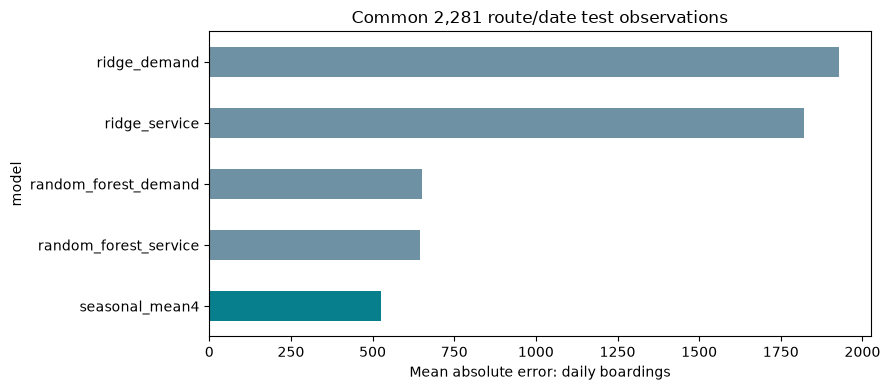

In [4]:
test = scores[scores['split'].eq('test')].set_index('model')
ax = test.MAE.sort_values().plot.barh(color=['#087f8c'] + ['#6e92a4'] * 4, figsize=(9,4))
ax.set_xlabel('Mean absolute error: daily boardings')
ax.set_title('Common 2,281 route/date test observations')
plt.tight_layout()
plt.show()

In [5]:
pd.read_csv(folder / 'day_type_errors.csv').query("split == 'test'").round(3)

,split,model,day_type,rows,MAE,RMSE,WAPE
0,test,random_forest_demand,Saturday,280,743.773,1218.293,0.180
1,test,random_forest_demand,Sunday,280,535.537,773.321,0.148
2,test,random_forest_demand,Weekday,1721,653.333,1057.874,0.109
3,test,random_forest_service,Saturday,280,737.932,1219.718,0.179
4,test,random_forest_service,Sunday,280,526.650,762.337,0.146
5,test,random_forest_service,Weekday,1721,648.090,1049.809,0.108
6,test,ridge_demand,Saturday,280,1663.150,1963.202,0.403
7,test,ridge_demand,Sunday,280,1482.042,1645.749,0.410
8,test,ridge_demand,Weekday,1721,2044.081,2279.048,0.340
9,test,ridge_service,Saturday,280,1614.899,1919.061,0.392


## Interpretation and serving decision

Adding schedule features reduced Random Forest MAE from 649.98 to 644.21 (about 0.89%). The seasonal baseline achieved 524.77 and outperformed both. The schedule-aware candidate therefore does not justify replacing the serving bundle. These numbers cannot be compared directly with the earlier 2,501-row experiment because both training coverage and test population differ.

Supply features describe scheduled service, not actual delays or occupancy. The existing replay model and its immutable registrations remain unchanged. More data or model complexity is not automatically an improvement.